# Contador sin lock

Este notebook grafica los resultados del contador **sin ningún mecanismo de sincronización** que se presentaron en clase (diapositivas, p. 7): cada hilo incrementa un millón de veces el mismo contador compartido.

Los datos están escritos directamente en el notebook porque son los de la tabla de las diapositivas. Los valores que se obtienen al ejecutar `./counter_test` en otra máquina (o en otra ejecución) serán distintos: la race condition no es determinista.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# Datos de la tabla de las diapositivas (p. 7)
data = {
    "Número de hilos": [1, 2, 4, 8, 16],
    "Valor esperado": [1_000_000, 2_000_000, 4_000_000, 8_000_000, 16_000_000],
    "Valor obtenido": [1_000_000, 1_030_174, 1_033_970, 1_309_698, 1_177_806],
    "Tiempo (s)": [0.004213, 0.004213, 0.025465, 0.044530, 0.088573],
}
df = pd.DataFrame(data)
df["Incrementos perdidos (%)"] = ((1 - df["Valor obtenido"] / df["Valor esperado"]) * 100).round(1)
df

,Número de hilos,Valor esperado,Valor obtenido,Tiempo (s),Incrementos perdidos (%)
0,1,1000000,1000000,0.004213,0.0
1,2,2000000,1030174,0.004213,48.5
2,4,4000000,1033970,0.025465,74.2
3,8,8000000,1309698,0.044530,83.6
4,16,16000000,1177806,0.088573,92.6


## 1. Valor esperado vs. valor obtenido

Con un solo hilo el resultado es correcto. Con dos o más, el valor obtenido queda muy por debajo del esperado: los incrementos que se pierden son los que se sobrescriben cuando dos hilos leen el mismo valor de `value` antes de que alguno escriba el resultado (race condition).

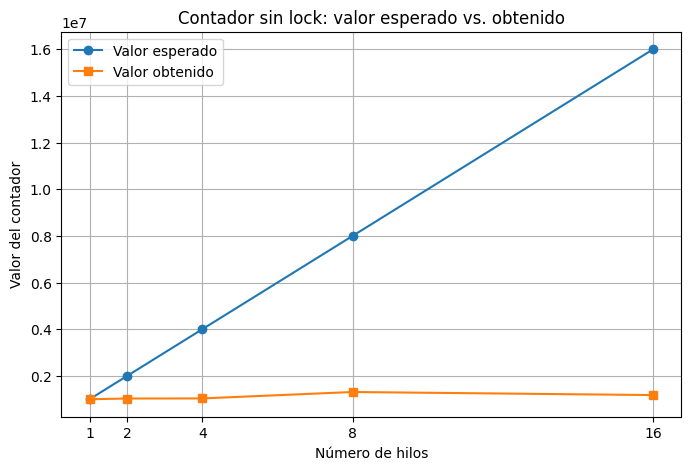

In [3]:
plt.figure(figsize=(8, 5))
plt.plot(df["Número de hilos"], df["Valor esperado"], marker="o", label="Valor esperado")
plt.plot(df["Número de hilos"], df["Valor obtenido"], marker="s", label="Valor obtenido")
plt.title("Contador sin lock: valor esperado vs. obtenido")
plt.xlabel("Número de hilos")
plt.ylabel("Valor del contador")
plt.xticks(df["Número de hilos"])
plt.legend()
plt.grid(True)
plt.show()

## 2. Porcentaje de incrementos perdidos

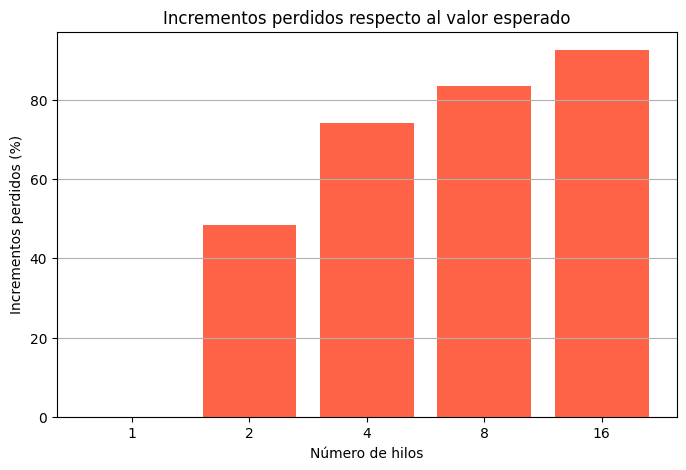

In [4]:
plt.figure(figsize=(8, 5))
plt.bar(df["Número de hilos"].astype(str), df["Incrementos perdidos (%)"], color="tomato")
plt.title("Incrementos perdidos respecto al valor esperado")
plt.xlabel("Número de hilos")
plt.ylabel("Incrementos perdidos (%)")
plt.grid(axis="y")
plt.show()

## 3. Tiempo de ejecución

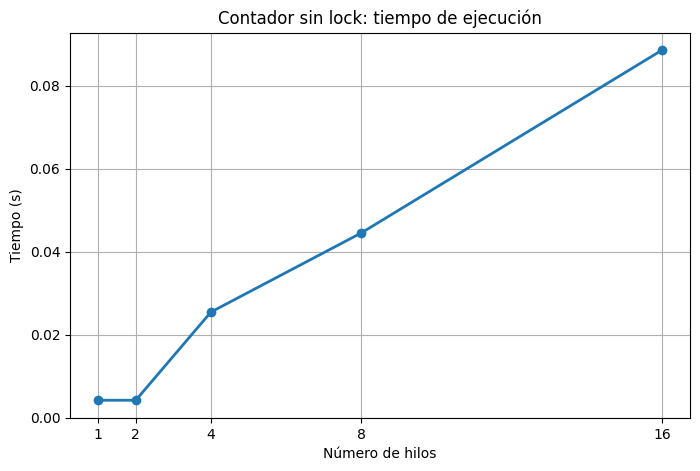

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(df["Número de hilos"], df["Tiempo (s)"], marker="o", linewidth=2)
plt.title("Contador sin lock: tiempo de ejecución")
plt.xlabel("Número de hilos")
plt.ylabel("Tiempo (s)")
plt.xticks(df["Número de hilos"])
plt.grid(True)
plt.show()

## Conclusiones

- `c->value++` no es una operación atómica: se compila como leer, sumar y escribir, y dos hilos pueden intercalarse entre esos pasos.
- Con más de un hilo se pierde la mayor parte de los incrementos, y la cantidad perdida cambia de una ejecución a otra.
- El programa es rápido porque no hay sincronización, pero el resultado es incorrecto. El siguiente paso es el contador preciso (`../precise_counter/`), que protege la región crítica con un lock.